In [1]:
from IPython.display import Image, display

# Preprocessing of scRNA-seq data

Two essential properties of scRNA-seq datasets:
- Contains drop-outs i.e., there is an excessive number of zeros in the data due to the limitation of mRNA.
- The potential for correcting the data and performing quality control might be limited as the data may be confounded with biology.

The main steps in preprocessing involves:
- **Doublet detection**
- **Quality control**
- **Normalization**
- **Feature selection**
- **Dimensionality reduction**

## Example analysis on single-cell multiomics data from bone marrow mononuclear cells of 12 healthy human donors measured at four different sites

In [2]:
from typing import Literal

import anndata as ad
import lamindb as ln
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
from rpy2.robjects import numpy2ri
from rpy2.robjects.conversion import localconverter
from scipy.sparse import csc_matrix
from scipy.special import logit
from scipy.stats import median_abs_deviation

# Suppress verbose logging from Scanpy
sc.settings.verbosity = 0

# Set figure parameters for clean, minimal plots
sc.set_figure_params(dpi=80, facecolor="white", frameon=False)

→ connected lamindb: anonymous/intermediate_data


In [3]:
# Loading the dataset
af = ln.Artifact.connect("theislab/sc-best-practices").get(
key="preprocessing_visualization/quality_control_adata.h5ad", is_latest=True
)
adata = af.load()
adata

! run input wasn't tracked, call `ln.track()` and re-run


/opt/anaconda3/envs/preprocessing/lib/python3.13/site-packages/lamindb/core/loaders.py:88: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = read_h5ad(file, backed=False, **kwargs)


AnnData object with n_obs × n_vars = 16934 × 36601
    var: 'gene_ids', 'feature_types', 'genome', 'interval'
    layers: None (.X)

In [4]:
# A warning shows that not all variable names (genes) are unique
adata.var_names_make_unique() # Makes the variable names unique by appending a number string to each duplicate index element: '1', '2', etc
adata

AnnData object with n_obs × n_vars = 16934 × 36601
    var: 'gene_ids', 'feature_types', 'genome', 'interval'
    layers: None (.X)

## Necessity of quality control

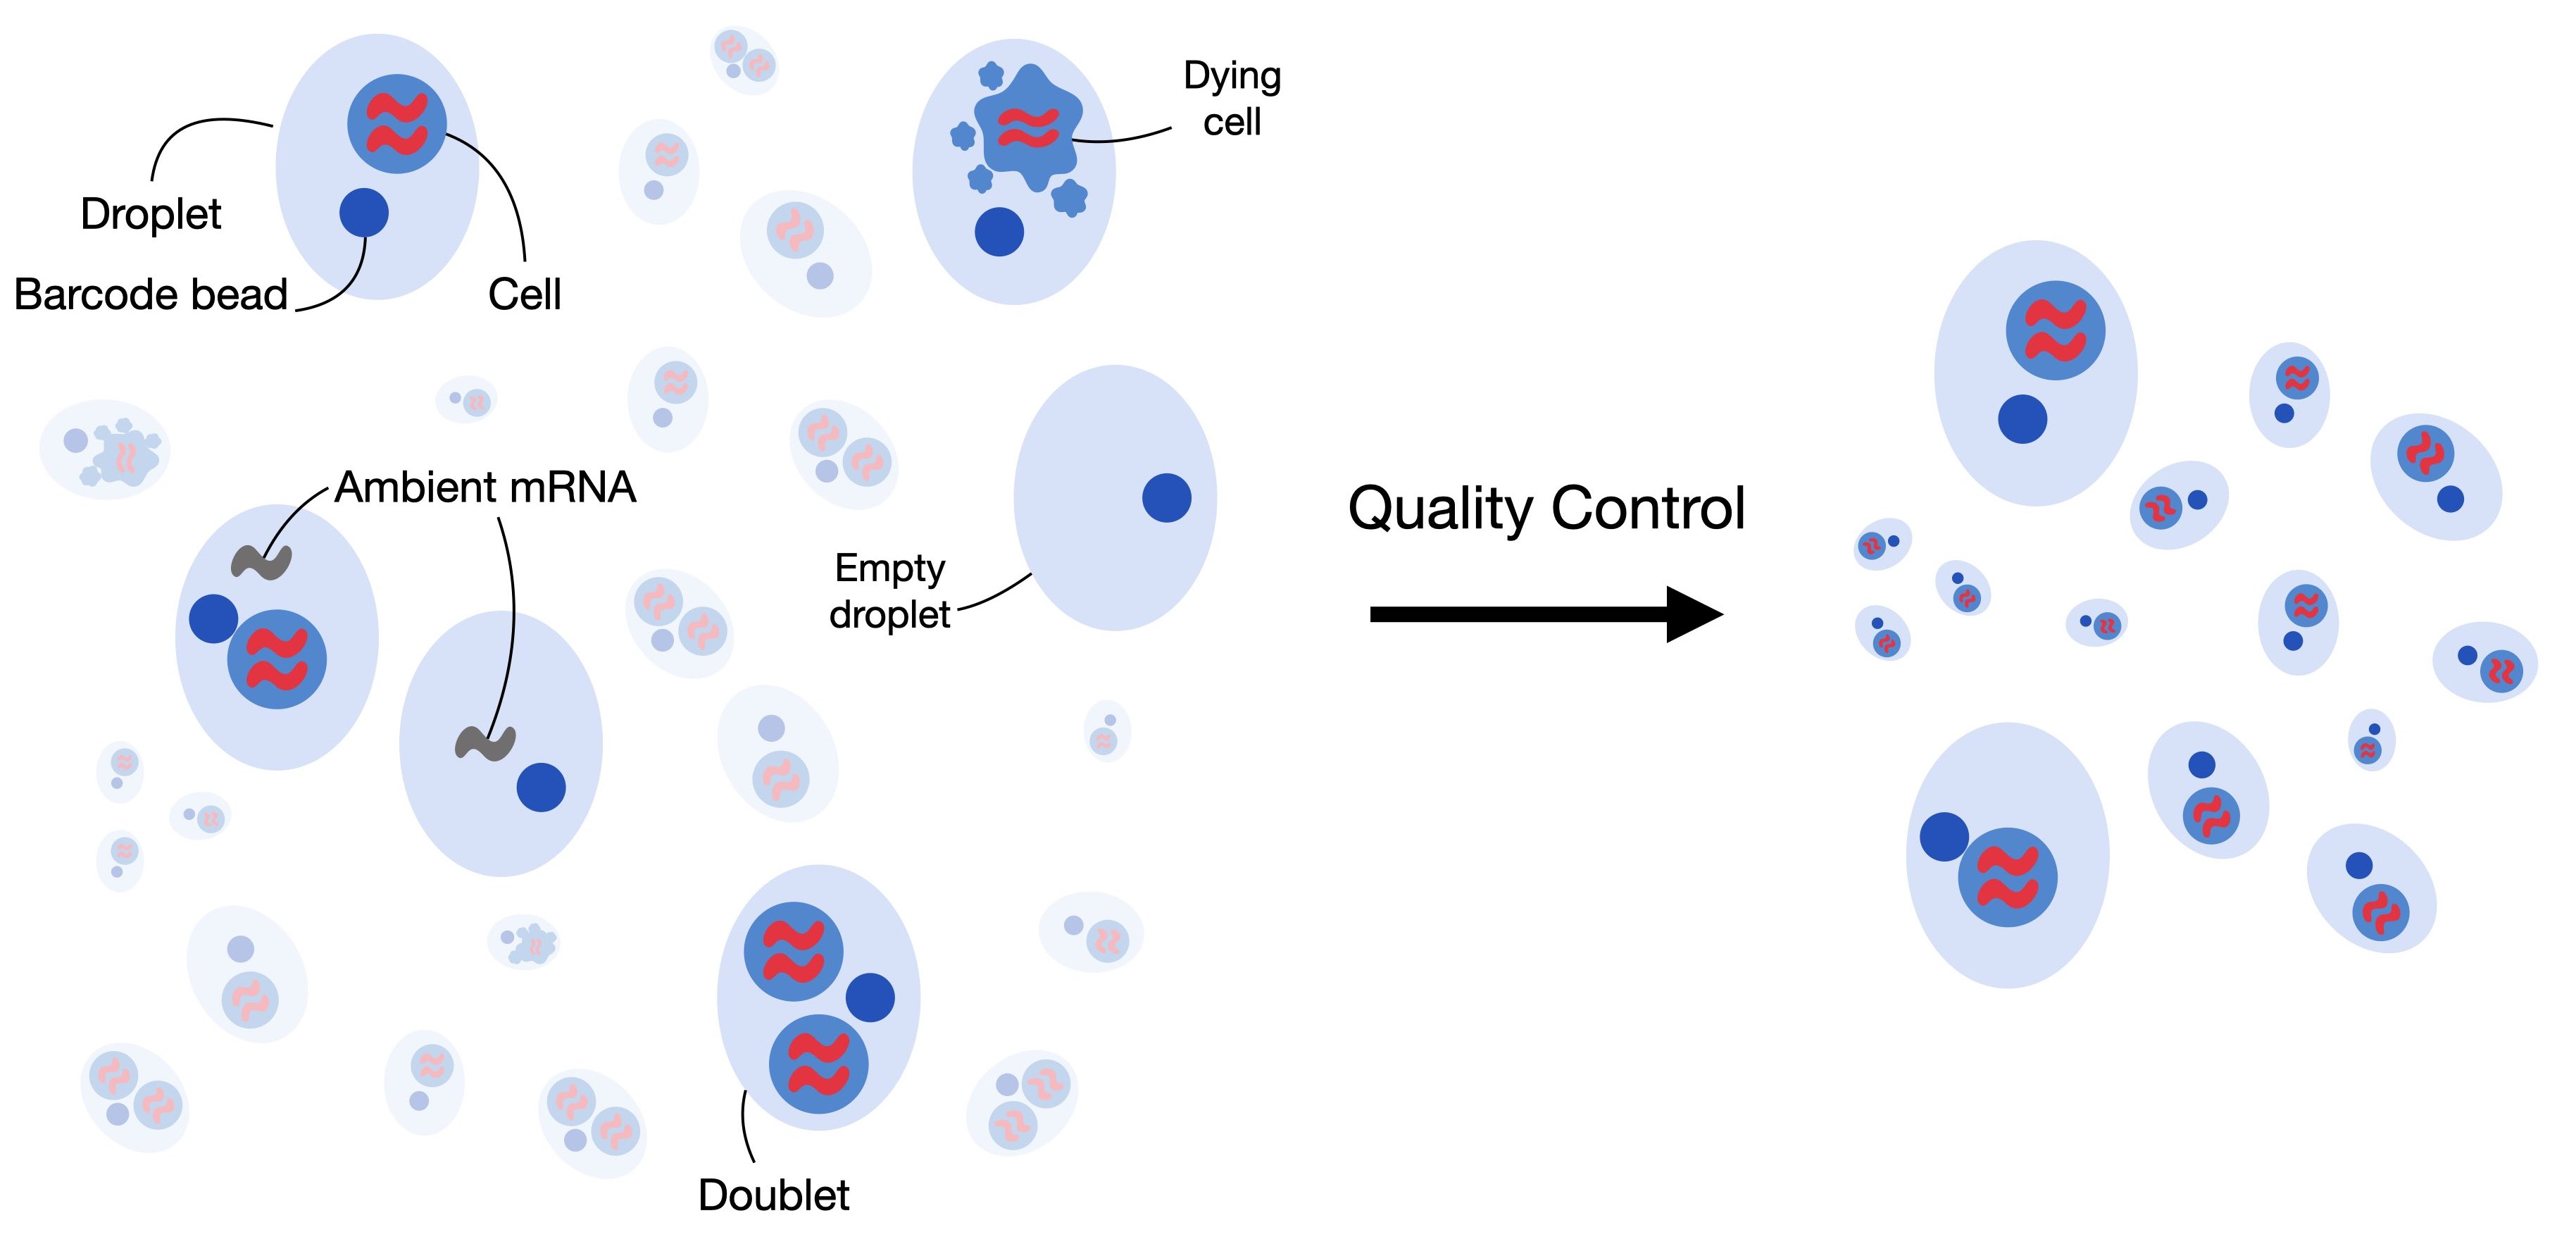

In [5]:
display(Image(filename="../../images/quality_control.jpeg"))

## Filtering low quality cells
- Signs of low quality cells
    - Low number of detected genes
    - A low count depth per cell
    - A high fraction of mitochondrial counts (Reflects cells with broken membranes whose cytoplasmic mRNA has leaked out, and therefore only the mRNA in the mitochondria is still present)
- Cell QC is performed on the following three QC covariates:
    - The number of counts per barcode (count depth)
    - The number of genes per barcode
    - The fraction of counts from mitochondrial genes per barcode

- Special cases:
    - Cells with a relatively high fraction of mitochondrial counts might be involved in respiratory processes and should not be filtered out.
    - Cells with low or high counts might correspond to quiescent cell populations or cells larger in size.

**It is therefore preferred to consider multiple covariates when thresholding decisions on single covariates are made. In general, it is advised to exclude fewer cells and be as permissive as possible to avoid filtering out viable cell populations or small sub-populations.**

- QC on small datasets can be performed manually by looking at the distribution of different QC covariates and identifying outliers.
- Large datasets, however, needs automatic thresholding via **MAD (median absolute deviations)**. We can mark cells as outliers if they differ by 5 MADs which is a permissive filtering strategy.
- It might be reasonable to re-assess the filtering after the annotation of cells.
- Other QCs:
    - A high fraction of hemoglobin counts points at contamination with red blood cells.
    - The ribosomal fraction varies with cell state and can help explain what separates clusters based on it.

In [6]:
# mitochondrial genes
adata.var["mt"] = adata.var_names.str.startswith("MT-")
# ribosomal genes
adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL"))
# hemoglobin genes
adata.var["hb"] = adata.var_names.str.contains(r"^HB[ABDEGMQZ]\d*(?!\w)")

In [7]:
# Calculating the QC metrics
sc.pp.calculate_qc_metrics(
    adata, qc_vars=["mt", "ribo", "hb"], inplace=True, percent_top=[20], log1p=True
)
adata

AnnData object with n_obs × n_vars = 16934 × 36601
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    layers: None (.X)

Important columns added by the "calculate qc metrics" function
- **n_genes_by_counts** in **.obs** is the number of genes with positive counts in a cells
- **total_counts** is the total number of counts for a cell, this might also be known as library size
- **pct_counts_mt** is the proportion of total counts for a cell which are mitochondrial
- The boolean **mt**, **ribo** and **hb** flags in **.var** define which genes are summed into **total_count_mt**, **pct_counts_mt** and the corresponding ribosomal and hemoglobin columns.

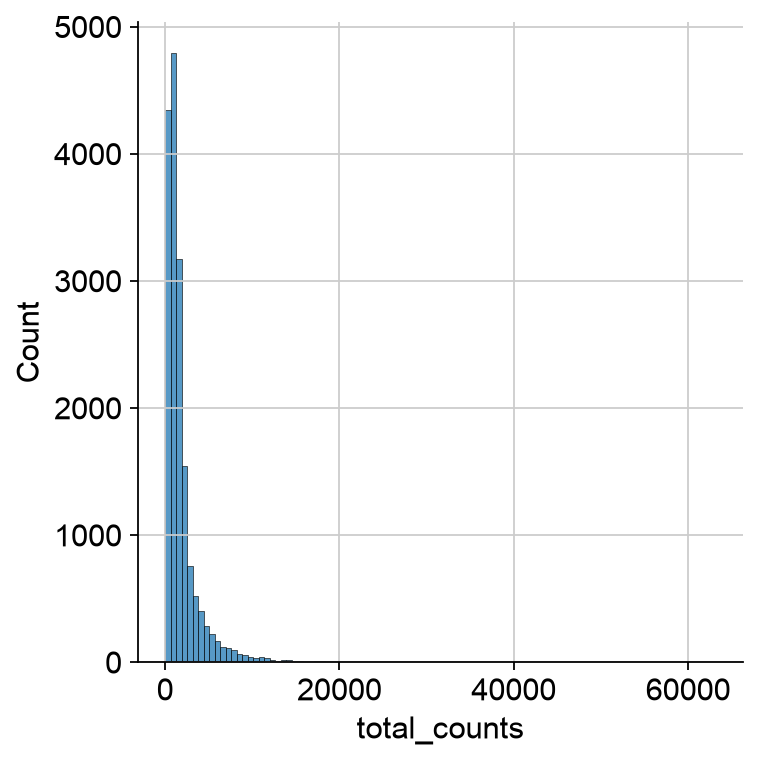

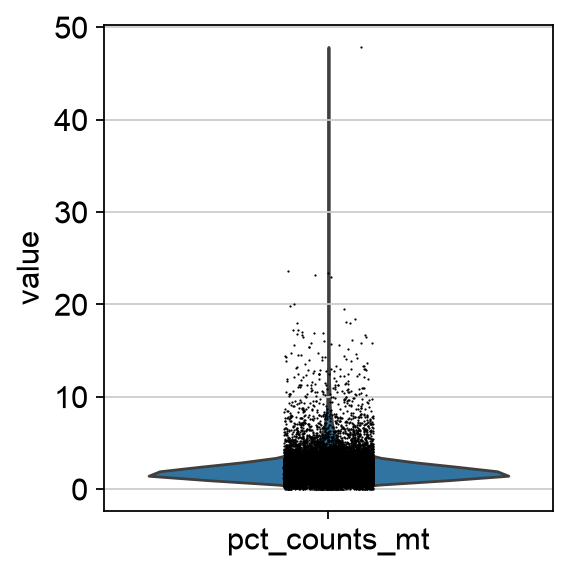

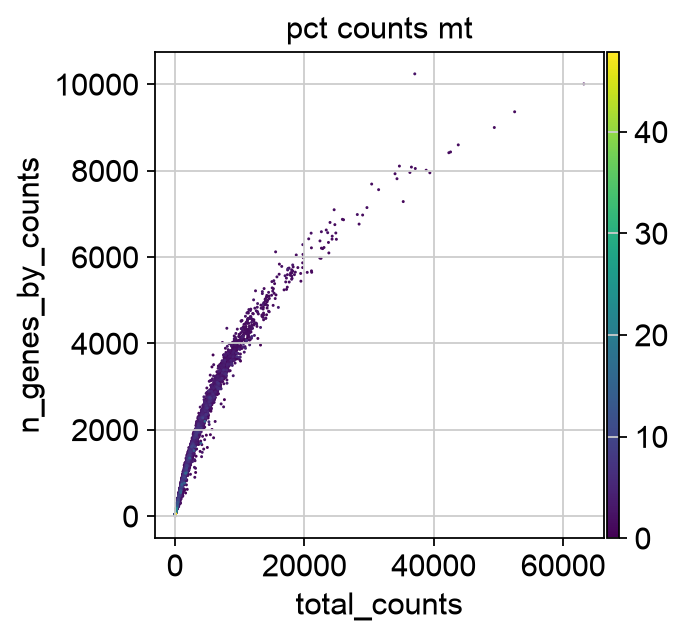

In [8]:
# Plotting the three QC covariates
p1 = sns.displot(adata.obs["total_counts"], bins=100, kde=False)
p2 = sc.pl.violin(adata, "pct_counts_mt")
p3 = sc.pl.scatter(adata, "total_counts", "n_genes_by_counts", color="pct_counts_mt")

- The p2 plot indicates that some cells have a relatively high percentage of mitochondrial counts.
- Since the number of counts per cell is sufficiently high and the percentage of mitochondrial counts is for most cells below 20%, we can still process the data.

In [9]:
def mad_thresholds(values: pd.Series, nmads:float) -> tuple[float, float]:
    """Thresholds `nmads` median absolute deviations below and above the median of `values`."""
    median, mad = np.median(values), median_abs_deviation(values)
    return median - nmads * mad, median + nmads * mad

def is_outlier(
    adata: ad.AnnData,
    metric: str,
    nmads: float,
    side: Literal["both","upper"] = "both",
) -> pd.Series:
    """Flag the cells beyond the MAD thresholds of `metric`, on both sides or only above,"""
    values = adata.obs[metric]
    lower, upper = mad_thresholds(values, nmads)
    return values > upper if side == "upper" else (values < lower) | (values > upper)

- The bounded and skewed mitochondrial fraction is logit-transformed before computing MADs.
- A pseudocount keeps cells without mitochondrial counts finite.

In [10]:
mt_fraction = (adata.obs["total_counts_mt"] + 1) / (adata.obs["total_counts"] + 2)
adata.obs["logit_mt_fraction"] = logit(mt_fraction)

- Using 5 MADs for total_counts, n_genes_by_counts and pct_counts
- For mitochondrial fraction, flag cells that exceed both 3 MADs and a fixed cutoff of 8% which is not universal since mitochondrial content differs between cell types and tissues

In [11]:
qc_filters = {
    "log1p_total_counts": (5, "both"),
    "log1p_n_genes_by_counts": (5, "both"),
    "pct_counts_in_top_20_genes": (5, "both"),
    "logit_mt_fraction":(3, "upper"),
}

flags = {
    metric: is_outlier(adata, metric, nmads, side)
    for metric, (nmads, side) in qc_filters.items()
}
adata.obs["outlier"] = (
    flags["log1p_total_counts"]
    | flags["log1p_n_genes_by_counts"]
    | flags["pct_counts_in_top_20_genes"]
)
adata.obs["mt_outlier"] = flags["logit_mt_fraction"] & (adata.obs["pct_counts_mt"] > 8)
adata.obs[["outlier", "mt_outlier"]].value_counts()

outlier  mt_outlier
False    False         15998
True     False           679
         True            190
False    True             67
Name: count, dtype: int64

In [12]:
flags

{'log1p_total_counts': AAACAGCCAAGCTTAT-1    False
 AAACAGCCATAGCTTG-1    False
 AAACAGCCATGAAATG-1    False
 AAACAGCCATGTTTGG-1    False
 AAACATGCAACGTGCT-1    False
                       ...  
 TTTGTTGGTGGCTTCC-1    False
 TTTGTTGGTTCTTTAG-1    False
 TTTGTTGGTTGGCCGA-1    False
 TTTGTTGGTTTACTTG-1    False
 TTTGTTGGTTTGTGGA-1    False
 Name: log1p_total_counts, Length: 16934, dtype: bool,
 'log1p_n_genes_by_counts': AAACAGCCAAGCTTAT-1    False
 AAACAGCCATAGCTTG-1    False
 AAACAGCCATGAAATG-1    False
 AAACAGCCATGTTTGG-1    False
 AAACATGCAACGTGCT-1    False
                       ...  
 TTTGTTGGTGGCTTCC-1    False
 TTTGTTGGTTCTTTAG-1    False
 TTTGTTGGTTGGCCGA-1    False
 TTTGTTGGTTTACTTG-1    False
 TTTGTTGGTTTGTGGA-1    False
 Name: log1p_n_genes_by_counts, Length: 16934, dtype: bool,
 'pct_counts_in_top_20_genes': AAACAGCCAAGCTTAT-1    False
 AAACAGCCATAGCTTG-1    False
 AAACAGCCATGAAATG-1     True
 AAACAGCCATGTTTGG-1    False
 AAACATGCAACGTGCT-1    False
                       

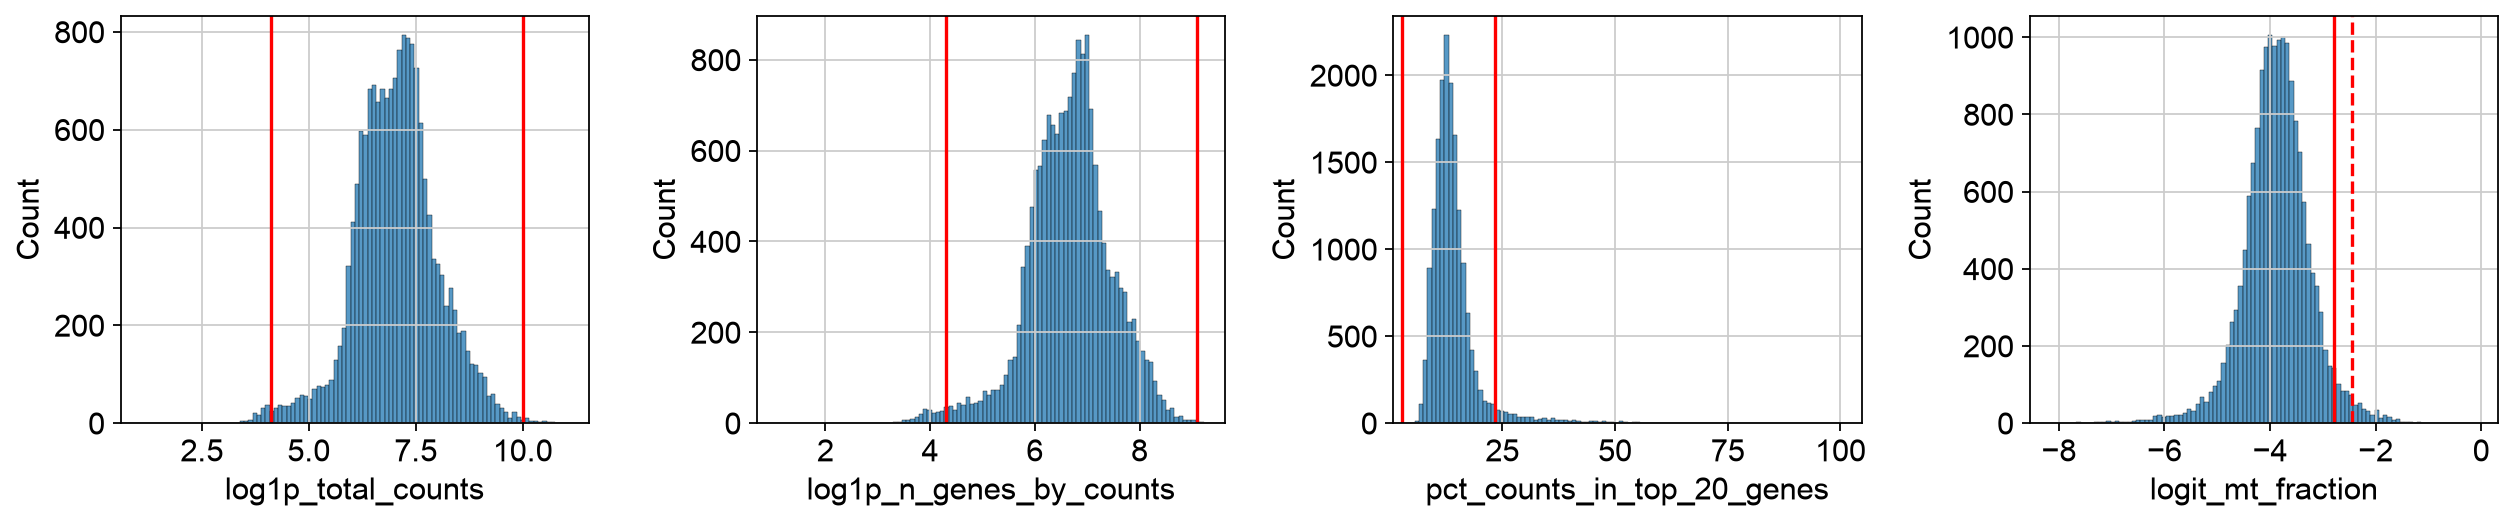

In [13]:
# Plotting the thresholds
fig, axes = plt.subplots(1, len(qc_filters), figsize=(16, 3.5))

for ax, (metric, (nmads, side)) in zip(axes, qc_filters.items(), strict=True):
    sns.histplot(adata.obs[metric], bins=100, ax=ax)
    lower, upper = mad_thresholds(adata.obs[metric], nmads)
    for threshold in [upper] if side == "upper" else [lower, upper]:
        ax.axvline(threshold, color="red")
axes[-1].axvline(logit(0.08), color="red", linestyle="--") # 8 % cutoff
plt.tight_layout()
plt.show()

In [14]:
# Filtering the AnnData object
print(f"Total number of cells: {adata.n_obs}")
adata_filtered = adata[(~adata.obs.outlier) & (~adata.obs.mt_outlier)].copy()

print(f"Number of cells after filtering of low quality cells: {adata_filtered.n_obs}")

Total number of cells: 16934
Number of cells after filtering of low quality cells: 15998


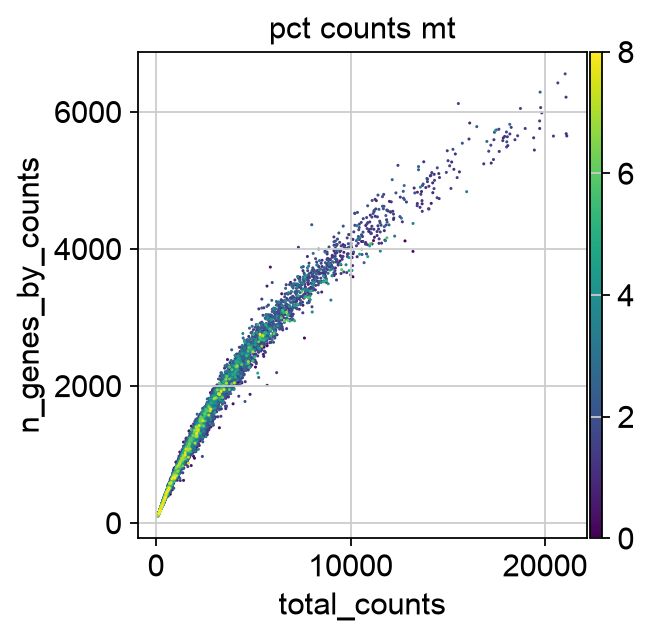

In [15]:
pl = sc.pl.scatter(adata_filtered, "total_counts", "n_genes_by_counts", color="pct_counts_mt")

# Correction of ambient RNA
- Only applies to **droplet-based protocols**.
- A certain amount of background mRNAs (cell-free mRNAs) is present in the dilution that gets distributed into the droplets with cells and sequenced along with them.
- Methods for removal of ambient mRNA like **SoupX** and **DecontX** aim to estimate the composition of the soup (term for contamination of cell-free mRNA in the input solution) and correct the count table with respect to the soup-based expression.

N.B.: SoupX works better if a basic clustering is provided.

In [16]:
# Loading the required python and R packages needed for running SoupX
import logging

import rpy2.rinterface_lib.callbacks as rcb
import rpy2.robjects as ro
from rpy2.robjects import pandas2ri

rcb.logger.setLevel(logging.ERROR)

%load_ext rpy2.ipython

In [17]:
%%R
library(SoupX)

In [18]:
# Normalize and lop1p transform the data
adata_pp = adata_filtered.copy()
sc.pp.normalize_total(adata_pp, target_sum=1e4)
sc.pp.log1p(adata_pp)

In [19]:
# Computing the principal components of the data
# which in turn is used to generate a neighborhood graph
# and then run leiden clustering on the KNN-graph
sc.pp.pca(adata_pp)
sc.pp.neighbors(adata_pp)
sc.tl.leiden(
    adata_pp, key_added="soupx_groups", flavor="igraph", n_iterations=2, directed=False
)

# Preprocess variables for SoupX
adata_filtered.obs["soupx_groups"] = adata_pp.obs["soupx_groups"]

In [20]:
adata_filtered

AnnData object with n_obs × n_vars = 15998 × 36601
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'logit_mt_fraction', 'outlier', 'mt_outlier', 'soupx_groups'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    layers: None (.X)

In [21]:
cells = adata_filtered.obs_names
genes = adata_filtered.var_names

# SoupX requires a matrix of shape features x barcodes, so we have to transpose .X
data = csc_matrix(adata_filtered.X.T)

In [22]:
adata_raw = af.load()

adata_raw.var_names_make_unique()
if not adata_raw.obs_names.is_unique or not cells.is_unique:
    raise ValueError("SoupX requires unique droplet and cell barcodes.")
if not genes.isin(adata_raw.var_names).all():
    raise ValueError("Raw droplets are missing genes from adata_filtered; check the reference/sample.")
if not cells.isin(adata_raw.obs_names).all():
    raise ValueError("Filtered cell barcodes are missing from raw droplets; use the matching channel.")

# Both matrices must contain the same genes in exactly the same order.
adata_raw = adata_raw[:, genes].copy()
genes_raw = adata_raw.var_names
cells_raw = adata_raw.obs_names

data_tod = csc_matrix(adata_raw.X.T)

! run input wasn't tracked, call `ln.track()` and re-run


/opt/anaconda3/envs/preprocessing/lib/python3.13/site-packages/lamindb/core/loaders.py:88: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = read_h5ad(file, backed=False, **kwargs)


In [23]:
# Transfer COO coordinates as explicit R vectors. This avoids CSC pointer slots
# and NumPy arrays retaining an R 'array' class during conversion.
def transfer_sparse(prefix, matrix):
    coo = matrix.tocoo()
    ro.globalenv[f"{prefix}_i"] = ro.IntVector(coo.row)
    ro.globalenv[f"{prefix}_j"] = ro.IntVector(coo.col)
    ro.globalenv[f"{prefix}_x"] = ro.FloatVector(coo.data)
    ro.globalenv[f"{prefix}_dims"] = ro.IntVector(coo.shape)

transfer_sparse("toc", data)
transfer_sparse("tod", data_tod)

ro.globalenv["genes"] = ro.StrVector(genes.tolist())
ro.globalenv["cells"] = ro.StrVector(cells.tolist())
ro.globalenv["cells_raw"] = ro.StrVector(cells_raw.tolist())

clusters = adata_filtered.obs["soupx_groups"]
ro.globalenv["soupx_groups"] = ro.StrVector(clusters.astype(str).tolist())

SoupX inputs:
- Unnormalized count matrix: genes × retained cells.
- Unfiltered droplet count matrix: the same genes × all droplets, including empty droplets.
- Matching gene names, barcodes, and Leiden clusters.

The next cells estimate contamination and store corrected counts in `adata_filtered.layers["soupx"]`, preserving the original counts in `.X`.

In [24]:
%%R
library(SoupX)
library(Matrix)

data <- sparseMatrix(
    i = toc_i, j = toc_j, x = toc_x, dims = toc_dims,
    dimnames = list(genes, cells), index1 = FALSE
)
data_tod <- sparseMatrix(
    i = tod_i, j = tod_j, x = tod_x, dims = tod_dims,
    dimnames = list(genes, cells_raw), index1 = FALSE
)

clusters <- setNames(as.character(soupx_groups), colnames(data))
soupx_channel <- SoupX::SoupChannel(data_tod, data, calcSoupProfile = TRUE)
soupx_channel <- SoupX::setClusters(soupx_channel, clusters)
soupx_channel <- SoupX::autoEstCont(soupx_channel, doPlot = FALSE)
out <- SoupX::adjustCounts(soupx_channel, roundToInt = TRUE)

561 genes passed tf-idf cut-off and 222 soup quantile filter.  Taking the top 100.
Using 873 independent estimates of rho.
Estimated global rho of 0.05
Expanding counts from 17 clusters to 15998 cells.
In addition: Warning message:
In sparseMatrix(i = out@i[w] + 1, j = out@j[w] + 1, x = out@x[w],  :
  'giveCsparse' is deprecated; setting repr="T" for you


In [25]:
# Retrieve sparse slots explicitly; an R S4 matrix is not automatically a SciPy matrix.
# SoupX returns genes x cells; AnnData layers require cells x genes.
out_r = ro.globalenv["out"]
out_shape = tuple(np.asarray(out_r.slots["Dim"], dtype=int))
corrected = csc_matrix((
    np.asarray(out_r.slots["x"], dtype=np.float64),
    np.asarray(out_r.slots["i"], dtype=np.int32),
    np.asarray(out_r.slots["p"], dtype=np.int32),
), shape=out_shape).T.tocsr()

adata_filtered.layers["soupx"] = corrected
print(f"Stored corrected counts in adata_filtered.layers['soupx']: {corrected.shape}")

Stored corrected counts in adata_filtered.layers['soupx']: (15998, 36601)


In [26]:
# Additionally filtering out genes that are not detected in at least 20 cells
print(f"Total number of genes: {adata_filtered.n_vars}")

sc.pp.filter_genes(adata_filtered, min_cells=20)
print(f"Number of genes after cell filter: {adata_filtered.n_vars}")
# The number of genes after cell filter might vary between runs due to differences in the random number generator (RNG) state

Total number of genes: 36601
Number of genes after cell filter: 20671


In [27]:
adata_filtered

AnnData object with n_obs × n_vars = 15998 × 20671
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'logit_mt_fraction', 'outlier', 'mt_outlier', 'soupx_groups'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    layers: None (.X), 'soupx'

# Doublet Detection
- Defined as two cells that are sequenced under the same barcode, for example, if they are captured in the same droplet.
- A doublet is called **homotypic** if it is formed by the same cell type (but from different individuals) and **heterotypic** if it formed from different cell types or states.
- Homotypic doublets are not identifiable from count matrices and are considered harmless as they can be identified with cell hashing (using oligo-tagged antibodies) or SNP-based demultiplexing. Hence, their identification is not the mail goal of doublet detection methods.
- Identification of heterotypic doublets is crucial. They can be identified either through their high number of reads and detected features, or with methods that create artificial doublets and compare these with the cells present in the dataset.
- Benchmarking of different doublet detection methods assessed `scDblFinder` with the highest doublet detection accuracy and a good computational efficiency and stability.
- Has to be run per sample as doublets only form between cells captured together.
- In plate-based protocols such as Smart-seq2, cells are sorted into separate wells, so doublets are much rarer than in droplets and ambient RNA correction does not apply.
- Doublet detection should not be run on aggregated scRNA-seq data representing multiple batches.

## scDblFinder
- Generate artificial doublets by randomly subsampling pairs of cells and averaging their gene expression profile to obtain doublet counts.
- These artificial doublets are projected together with the remaining cells into a lower dimensional principal component space.
- A doublet score is calculated based on the number of artificial doublet neighbors in the k-nearest neighbor graph.

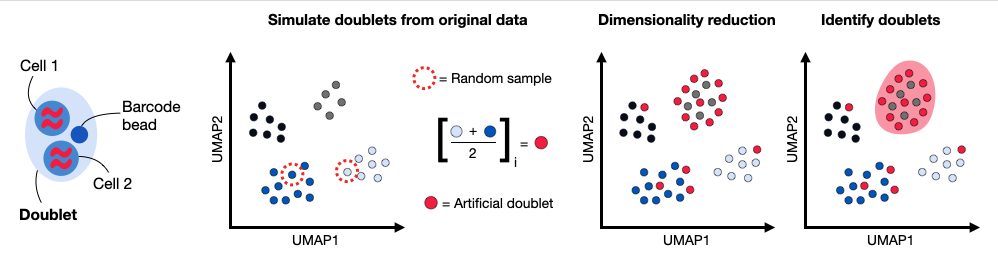

In [28]:
display(Image("../../images/doublet_detection.jpeg"))

In [29]:
%%R
library(scater)
library(scDblFinder)
library(SingleCellExperiment)
library(BiocParallel)

Loading required package: SingleCellExperiment
Loading required package: SummarizedExperiment
Loading required package: MatrixGenerics
Loading required package: matrixStats

Attaching package: ‘MatrixGenerics’

The following objects are masked from ‘package:matrixStats’:

    colAlls, colAnyNAs, colAnys, colAvgsPerRowSet, colCollapse,
    colCounts, colCummaxs, colCummins, colCumprods, colCumsums,
    colDiffs, colIQRDiffs, colIQRs, colLogSumExps, colMadDiffs,
    colMads, colMaxs, colMeans2, colMedians, colMins, colOrderStats,
    colProds, colQuantiles, colRanges, colRanks, colSdDiffs, colSds,
    colSums2, colTabulates, colVarDiffs, colVars, colWeightedMads,
    colWeightedMeans, colWeightedMedians, colWeightedSds,
    colWeightedVars, rowAlls, rowAnyNAs, rowAnys, rowAvgsPerColSet,
    rowCollapse, rowCounts, rowCummaxs, rowCummins, rowCumprods,
    rowCumsums, rowDiffs, rowIQRDiffs, rowIQRs, rowLogSumExps,
    rowMadDiffs, rowMads, rowMaxs, rowMeans2, rowMedians, rowMins,
    rowOr

In [30]:
data_mat = adata_filtered.X.T

`scDblFinder` adds several columns to the colData of sce. Important ones include:
- `sce$scDblFinder.score`: the final doublet score (the higher the more likely that the cell is a doublet)
- `sce$scDblFinder.ratio` : the ratio of artificial doublets in the cell’s neighborhood
- `sce$scDblFinder.class` : the classification (doublet or singlet)

In [31]:
# Converting the matrix from python to R
data_mat = adata_filtered.X.T.tocsc()

x = data_mat.data.astype(np.float64)
i = data_mat.indices.astype(np.int32)
p = data_mat.indptr.astype(np.int32)
dims = np.array(data_mat.shape, dtype=np.int32)

with localconverter(ro.default_converter + numpy2ri.converter):
    ro.globalenv["x"] = x
    ro.globalenv["i"] = i
    ro.globalenv["p"] = p
    ro.globalenv["dims"] = dims

In [32]:
%%R -o doublet_score -o doublet_class

x <- as.numeric(x)
i <- as.integer(i)
p <- as.integer(p)
dims <- as.integer(dims)

data_mat <- new("dgCMatrix", Dim = dims, x = x, i = i, p = p)

set.seed(123)
sce <- scDblFinder(SingleCellExperiment(list(counts = data_mat)))

doublet_score <- sce$scDblFinder.score
doublet_class <- sce$scDblFinder.class

Creating ~12799 artificial doublets...
Dimensional reduction
Evaluating kNN...
Training model...
iter=0, 3552 cells excluded from training.
iter=1, 3552 cells excluded from training.
iter=2, 3552 cells excluded from training.
Threshold found:0.457
2747 (17.2%) doublets called
In addition: There were 16 warnings (use warnings() to see them)


In [33]:
adata_filtered.obs["scDblFinder_score"] = doublet_score
adata_filtered.obs["scDblFinder_class"] = doublet_class
adata_filtered.obs.scDblFinder_class.value_counts()

scDblFinder_class
singlet    13251
doublet     2747
Name: count, dtype: int64

In [ ]:
from pathlib import Path

output_dir = Path("../intermediate_data")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / "quality_control.h5ad"

# Save AnnData directly to disk, including metadata and the SoupX layer.
adata_filtered.write_h5ad(output_path, compression="gzip")
print(f"Saved quality-controlled dataset to: {output_path.resolve()}")